# Quran & Hadith Research Agent
Flow: **Query Enhancer** -> 3 parallel **Researchers** (Quran, Hadith, Web), each with a **Grader** -> **Synthesizer** <-> **Reflector** -> answer with references.

## Setup

In [1]:
import operator
import os
import re
from typing import Annotated, List, Literal

from ddgs import DDGS
from dotenv import load_dotenv
from IPython.display import Image, display
from pydantic import BaseModel, Field

from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.messages import AnyMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings

from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Send

load_dotenv()

C:\Users\Nour_\AppData\Local\Temp\ipykernel_5196\2358261948.py:11: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS
d:\d\NLP\Quran-Companion-Arabic-Grounded-RAG-Agent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

## Quran data and vector store

In [2]:
import pickle, os
from langchain_community.document_loaders.csv_loader import CSVLoader
from langchain_core.documents import Document
from itertools import groupby
import re

CHUNKS_CACHE_PATH = "data/chunks_cache.pkl"

def normalize_arabic(text):
    if not text:
        return ""
    text = re.sub(r'[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED\u08D4-\u08FF]', '', text)
    text = text.replace("\u0640", "")
    text = re.sub(r'[\u0622\u0623\u0625\u0671]', '\u0627', text)
    text = re.sub(r'[\u0649\u06CC]', '\u064A', text)
    text = text.replace("\u0624", "\u0648")  # ؤ -> و
    text = text.replace("\u0626", "\u064A")  # ئ -> ي
    text = text.replace("\u0629", "\u0647")
    text = re.sub(r'[\u06DD\u06DE\u06E9\u08E2\u0660-\u0669\u06F0-\u06F9]', '', text)
    text = re.sub(r'[\ufd3e\ufd3f]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def chunk_quran_docs(docs, window_size=5, overlap=1):
    docs = sorted(docs, key=lambda d: (int(d.metadata["surah_no"]), int(d.metadata["ayah_no"])))
    chunks = []
    step = window_size - overlap

    for surah_no, group_iter in groupby(docs, key=lambda d: d.metadata["surah_no"]):
        group = list(group_iter)
        for start in range(0, len(group), step):
            window = group[start:start + window_size]
            if not window:
                break
            first, last = window[0], window[-1]
            text = " ".join(d.page_content for d in window)
            f_meta, l_meta = first.metadata, last.metadata
            ref = (f"{surah_no}:{f_meta['ayah_no']}"
                   if f_meta["ayah_no"] == l_meta["ayah_no"]
                   else f"{surah_no}:{f_meta['ayah_no']}-{l_meta['ayah_no']}")
            metadata = {
                "chunk_id": f"{int(surah_no):03d}_{int(f_meta['ayah_no']):03d}_{int(l_meta['ayah_no']):03d}",
                "surah_no": int(surah_no),
                "surah_name_ar": f_meta["surah_name_ar"],
                "surah_name_en": f_meta["surah_name_en"],
                "revelation_place": f_meta["revelation_place"],
                "start_ayah": int(f_meta["ayah_no"]),
                "end_ayah": int(l_meta["ayah_no"]),
                "reference": ref,
            }
            chunks.append(Document(page_content=text, metadata=metadata))
            if start + window_size >= len(group):
                break
    return chunks


if os.path.exists(CHUNKS_CACHE_PATH):
    with open(CHUNKS_CACHE_PATH, "rb") as f:
        chunks = pickle.load(f)
    print(f"Loaded {len(chunks)} chunks from cache: {CHUNKS_CACHE_PATH}")
else:
    loader = CSVLoader(
        file_path="data/Quran_RAG_Ready.csv",
        encoding="utf-8-sig",
        content_columns=["text_ar"],
        metadata_columns=["chunk_id", "surah_no", "surah_name_ar",
                           "surah_name_en", "revelation_place",
                           "ayah_no", "ayah_no_global", "reference"],
    )
    csv_docs = loader.load()
    print(f"Number of documents loaded: {len(csv_docs)}")

    for doc in csv_docs:
        doc.page_content = normalize_arabic(doc.page_content)

    chunks = chunk_quran_docs(csv_docs, window_size=5, overlap=1)

    with open(CHUNKS_CACHE_PATH, "wb") as f:
        pickle.dump(chunks, f)
    print(f"Total chunks: {len(chunks)} (cached to {CHUNKS_CACHE_PATH})")


Loaded 1573 chunks from cache: chunks_cache.pkl


In [3]:
print(chunks[0].page_content)
print("-"*50)
print(chunks[0].metadata)

text_ar: بسم الله الرحمن الرحيم text_ar: الحمد لله رب العالمين text_ar: الرحمن الرحيم text_ar: مالك يوم الدين text_ar: اياك نعبد واياك نستعين
--------------------------------------------------
{'chunk_id': '001_001_005', 'surah_no': 1, 'surah_name_ar': 'الفاتحة', 'surah_name_en': 'Al-Fatiha', 'revelation_place': 'Mecca', 'start_ayah': 1, 'end_ayah': 5, 'reference': '1:1-5'}


In [4]:
import torch
from langchain_huggingface import HuggingFaceEmbeddings

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Embedding device:", device)

embedding_model = HuggingFaceEmbeddings(
    model_name ="BAAI/bge-m3",
    model_kwargs={"device": device},
    encode_kwargs={"normalize_embeddings": True, "batch_size": 32},
)

Embedding device: cuda


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 29736.05it/s]


In [5]:
vectorstore = FAISS.load_local(
    "data/quran_faiss_index",
    embeddings=embedding_model,
    allow_dangerous_deserialization=True
)

print("FAISS loaded:", vectorstore is not None)
print("Index total vectors:", getattr(vectorstore.index, "ntotal", None))
print("Index dimension:", getattr(vectorstore.index, "d", None))

FAISS loaded: True
Index total vectors: 1573
Index dimension: 1024


## Tools

In [6]:
#tool 1: Quran verse search
QURAN_TOP_K = 3   # passages returned per search

@tool
def quran_search_tool(query: str) -> str:
    """Search a vector store of the full Holy Quran (Arabic text, all 114 surahs, 6,236 ayahs),
        grouped into passages of up to 5 consecutive ayahs.
        Use it for any question about Quranic verses, stories of the prophets (e.g. Musa, Ibrahim, Yusuf),
        Islamic teachings, rulings, or topics mentioned in the Quran.
        Input: a specific search query, preferably in Arabic (e.g. 'قصة البقرة مع قوم موسى' or 'الصبر عند المصيبة');
        English also works but Arabic gives better matches.
        Returns: the most relevant passages, each with its surah name and surah:ayah reference."""
    results = vectorstore.similarity_search(normalize_arabic(query), k=QURAN_TOP_K)
    return "\n\n".join(
            f"[{i}] Surah {d.metadata.get('surah_name_en', '')} ({d.metadata.get('surah_name_ar', '')}), "
            f"{d.metadata.get('reference', '?')}\n{d.page_content}"
            for i, d in enumerate(results, start=1)
        )

In [7]:
print(quran_search_tool.invoke("سورة كان سيدنا موسى  يأمر من قومه يذبحو بقرة بوحي من الله"))

[1] Surah Al-Baqara (البقرة), 2:65-69
text_ar: ولقد علمتم الذين اعتدوا منكم في السبت فقلنا لهم كونوا قرده خاسيين text_ar: فجعلناها نكالا لما بين يديها وما خلفها وموعظه للمتقين text_ar: واذ قال موسي لقومه ان الله يامركم ان تذبحوا بقره قالوا اتتخذنا هزوا قال اعوذ بالله ان اكون من الجاهلين text_ar: قالوا ادع لنا ربك يبين لنا ما هي قال انه يقول انها بقره لا فارض ولا بكر عوان بين ذلك فافعلوا ما تومرون text_ar: قالوا ادع لنا ربك يبين لنا ما لونها قال انه يقول انها بقره صفراء فاقع لونها تسر الناظرين

[2] Surah Ta-Ha (طه), 20:77-81
text_ar: ولقد اوحينا الي موسي ان اسر بعبادي فاضرب لهم طريقا في البحر يبسا لا تخاف دركا ولا تخشي text_ar: فاتبعهم فرعون بجنوده فغشيهم من اليم ما غشيهم text_ar: واضل فرعون قومه وما هدي text_ar: يا بني اسراييل قد انجيناكم من عدوكم وواعدناكم جانب الطور الايمن ونزلنا عليكم المن والسلوي text_ar: كلوا من طيبات ما رزقناكم ولا تطغوا فيه فيحل عليكم غضبي ومن يحلل عليه غضبي فقد هوي

[3] Surah Al-A'raf (الأعراف), 7:137-141
text_ar: واورثنا القوم الذين كانوا يستضعفون مشارق الارض 

In [8]:
### tool 2 duck duck search
WEB_TOP_K = 3   # web results returned per search

@tool
def duck_duck_search(query:str)->str:
    """Search the web with DuckDuckGo for information that is NOT in the Quran text itself.
    Use it for tafsir (scholarly explanations of verses), hadith, English translations of ayahs,
    the historical context or reasons of revelation (asbab al-nuzul), biographies of scholars or companions,
    current Islamic events and dates (e.g. 'Ramadan 2026 start date'), or anything the Quran search could not answer.
    Do NOT use it to find or quote Quranic verses themselves -- always use quran_search_tool for that,
    since it returns the exact Arabic text with surah:ayah references.
    Input: a concise search query, in English or Arabic, as you would type into a search engine
    (e.g. 'tafsir Ibn Kathir Al-Baqarah 67' or 'تفسير آية الكرسي').
    Returns: the top web results, each with a title, URL, and short snippet."""
    try:
        results = DDGS().text(query, max_results=WEB_TOP_K)
    except Exception as e:
        return f"Search failed: {e}"
    return "\n\n".join(
            f"[{i}] {r['title']} ({r['href']})\n{r['body']}"
            for i, r in enumerate(results, start=1)
        ) or "No web results."

In [9]:
print(duck_duck_search.invoke("سورة كان سيدنا موسى  يأمر من قومه يذبحو بقرة بوحي من الله"))

[1] تلاوة خاشعة لسورة البقرة بصوت سعد الغا مدي - YouTube (https://www.youtube.com/watch?v=ZFByVUGEtFA)
هنا أوحى الله جل علاه إلى نبيه موسى عليه السلام أن يطلب من قومه أن يذبحو بقرة لكن بني إسرائيل لم يقتنعو بالأمر بل وسخروا من نبي الله عليه السلام.

[2] سورة الرعد - الشيخ عثمان الخميس (https://othmanalkhamees.com/lesson/36)
صلى الله عليه وسلم كان يرقي الحسن والحسين يقول أعيذوك وما بكلمات الله التامة من كل شيطان هامة كنعي الله منك كان يرقي الحسن بعدين لما نزلت عليه سورة الفلق والناس صار يرقيه ما بهما ما في بس إن شاء الله دخل وقت دقيقة طيب الله أعلى وأعلم شكرا.

[3] قصة بقرة بني إسرائيل في زمن موسى عليه السلام | TikTok (https://www.tiktok.com/@daniahmed99/video/7370824971293068549)
Keywords: قصة بقرة بني إسرائيل التاريخية, دروس من قصة موسى, الخداع في قصة بني إسرائيل, أسرار سورة البقرة, تأثير الإيمان على الناس, أحداث تاريخية في القرآن الكريم, عبر من قصة موسى عليه السلام, أهمية الوحي في حياة بني إسرائيل...


### Tool 3: Hadith search (Sahih al-Bukhari, Arabic + English)

In [10]:
### Hadith API (fawazahmed0/hadith-api, free, no key required)
import requests, json, os

HADITH_BASE_URL = "https://cdn.jsdelivr.net/gh/fawazahmed0/hadith-api@1/editions"
HADITH_EDITIONS = {
    "eng": ("eng-bukhari", "data/hadith_bukhari_eng.json"),  # English translation of Sahih al-Bukhari
    "ara": ("ara-bukhari", "data/hadith_bukhari_ara.json"),  # Original Arabic text of Sahih al-Bukhari
}

def load_hadith_collection(edition, cache_path):
    if os.path.exists(cache_path):
        with open(cache_path, "r", encoding="utf-8") as f:
            return json.load(f)
    resp = requests.get(f"{HADITH_BASE_URL}/{edition}.json", timeout=60)
    resp.raise_for_status()
    data = resp.json()
    with open(cache_path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False)
    return data

eng_hadiths = load_hadith_collection(*HADITH_EDITIONS["eng"]).get("hadiths", [])
ara_hadiths = load_hadith_collection(*HADITH_EDITIONS["ara"]).get("hadiths", [])

# Merge both editions by hadith number so every record has Arabic + English text.
# text_ar_norm is the normalized Arabic used for matching Arabic queries.
ara_by_number = {h["hadithnumber"]: h.get("text", "") for h in ara_hadiths}
hadith_list = []
for h in eng_hadiths:
    text_ar = ara_by_number.get(h["hadithnumber"], "")
    hadith_list.append({
        "hadithnumber": h["hadithnumber"],
        "text_en": h.get("text", ""),
        "text_ar": text_ar,
        "text_ar_norm": normalize_arabic(text_ar),
    })

print(f"Loaded {len(eng_hadiths)} English and {len(ara_hadiths)} Arabic hadiths")
print(f"Merged records: {len(hadith_list)}, with Arabic text: {sum(1 for h in hadith_list if h['text_ar'])}")

Loaded 7589 English and 7589 Arabic hadiths
Merged records: 7589, with Arabic text: 7580


In [11]:
### Hadith vector store (bge-m3 + FAISS) -- built once, then loaded from disk
HADITH_INDEX_PATH = "data/hadith_faiss_index"
HADITH_MAX_CHARS = 2000   # cap very long hadiths to keep embedding fast

hadith_by_number = {h["hadithnumber"]: h for h in hadith_list}

if os.path.exists(HADITH_INDEX_PATH):
    hadith_vectorstore = FAISS.load_local(
        HADITH_INDEX_PATH, embeddings=embedding_model, allow_dangerous_deserialization=True
    )
    print(f"Loaded hadith index from {HADITH_INDEX_PATH}")
else:
    # Two documents per hadith (normalized Arabic + English) so both Arabic and
    # English queries match well; bge-m3 is multilingual, so cross-language queries work too.
    hadith_docs = []
    for h in hadith_list:
        if h["text_ar_norm"]:
            hadith_docs.append(Document(page_content=h["text_ar_norm"][:HADITH_MAX_CHARS],
                                        metadata={"hadithnumber": h["hadithnumber"], "lang": "ar"}))
        if h["text_en"]:
            hadith_docs.append(Document(page_content=h["text_en"][:HADITH_MAX_CHARS],
                                        metadata={"hadithnumber": h["hadithnumber"], "lang": "en"}))

    BATCH = 512
    hadith_vectorstore = None
    for i in range(0, len(hadith_docs), BATCH):
        batch = hadith_docs[i:i + BATCH]
        if hadith_vectorstore is None:
            hadith_vectorstore = FAISS.from_documents(batch, embedding_model)
        else:
            hadith_vectorstore.add_documents(batch)
        print(f"Embedded {min(i + BATCH, len(hadith_docs))}/{len(hadith_docs)}")

    hadith_vectorstore.save_local(HADITH_INDEX_PATH)
    print(f"Saved hadith index to {HADITH_INDEX_PATH}")

print("Hadith index vectors:", hadith_vectorstore.index.ntotal)

Loaded hadith index from hadith_faiss_index
Hadith index vectors: 15160


In [12]:
### Hadith Search Tool (semantic search, Arabic + English)
HADITH_TOP_K = 3   # hadiths returned per search

@tool
def hadith_search(query: str) -> str:
    """Search Sahih al-Bukhari hadiths by meaning (semantic search), in Arabic or English.
    Use this when the user asks about a hadith, or a saying/action of the Prophet
    Muhammad (peace be upon him), or wants a hadith to complement a Quranic answer.
    Input: a short description of the topic or the hadith wording, in Arabic or English
    (e.g. 'إنما الأعمال بالنيات', 'بر الوالدين', 'actions depend on intentions',
    'kindness to parents'). Exact wording is not required.
    Returns: the most relevant hadiths with their hadith numbers, each in both Arabic and English.
    """
    # Normalize the same way the Arabic hadiths were normalized before indexing
    # (no-op for English text).
    q = normalize_arabic(query)

    # Each hadith is indexed twice (ar + en), so over-fetch and dedupe by hadith number.
    results = hadith_vectorstore.similarity_search(q, k=HADITH_TOP_K * 4)
    seen, top = set(), []
    for d in results:
        n = d.metadata["hadithnumber"]
        if n not in seen:
            seen.add(n)
            top.append(hadith_by_number[n])
        if len(top) == HADITH_TOP_K:
            break

    if not top:
        return "No matching hadiths found."

    return "\n\n".join(
        f"Hadith #{h['hadithnumber']} (Sahih al-Bukhari):\n"
        f"AR: {h['text_ar'] or '(Arabic text unavailable)'}\n"
        f"EN: {h['text_en']}"
        for h in top
    )

In [13]:
print(hadith_search.invoke("i want hadith related to being good to my parents"))

Hadith #5979 (Sahih al-Bukhari):
AR: وَقَالَ اللَّيْثُ حَدَّثَنِي هِشَامٌ، عَنْ عُرْوَةَ، عَنْ أَسْمَاءَ، قَالَتْ قَدِمَتْ أُمِّي وَهْىَ مُشْرِكَةٌ فِي عَهْدِ قُرَيْشٍ وَمُدَّتِهِمْ، إِذْ عَاهَدُوا النَّبِيَّ صلى الله عليه وسلم مَعَ أَبِيهَا، فَاسْتَفْتَيْتُ النَّبِيَّ صلى الله عليه وسلم فَقُلْتُ إِنَّ أُمِّي قَدِمَتْ وَهْىَ رَاغِبَةٌ ‏{‏أَفَأَصِلُهَا‏}‏ قَالَ ‏ "‏ نَعَمْ صِلِي أُمَّكِ ‏"‏‏.‏
EN: Narrated Asma':"My mother who was a Mushrikah (pagan, etc.), came with her father during the period of peace pact between the Muslims and the Quraish infidels. I went to seek the advice of the Prophet (ﷺ) saying, "My mother has arrived and she is hoping (for my favor)." The Prophet (ﷺ) said, "Yes, be good to your mother

Hadith #2620 (Sahih al-Bukhari):
AR: حَدَّثَنَا عُبَيْدُ بْنُ إِسْمَاعِيلَ، حَدَّثَنَا أَبُو أُسَامَةَ، عَنْ هِشَامٍ، عَنْ أَبِيهِ، عَنْ أَسْمَاءَ بِنْتِ أَبِي بَكْرٍ ـ رضى الله عنهما ـ قَالَتْ قَدِمَتْ عَلَىَّ أُمِّي وَهْىَ مُشْرِكَةٌ، فِي عَهْدِ رَسُولِ اللَّهِ صلى الله عليه

## LLMs
`llm2` = Groq gpt-oss-120b, used by every graph node. `llm` = optional local Qwen3 14B (not used).

In [14]:
from langchain_ollama import ChatOllama

# Optional: local Qwen3 14B (Ollama) -- not used by the graph; swap it in to avoid Groq's rate limits.
llm = ChatOllama(model="qwen3:14b", temperature=0, reasoning=False, num_ctx=8192)

In [15]:
# Groq gpt-oss-120b -- used by every graph node.
# Free tier: 8k tokens/min, so on a rate limit (429) we wait and retry instead of crashing.
llm2 = ChatGroq(model="openai/gpt-oss-120b", max_retries=6)
RETRY = dict(wait_exponential_jitter=True, stop_after_attempt=6)

In [16]:
tools =[hadith_search,duck_duck_search,quran_search_tool]

## Graph states

In [17]:
### Graph states
# Flow: enhancer -> 3 researchers in parallel (one per tool) -> synthesizer <-> reflector -> final answer
ToolName = Literal["quran_search_tool", "hadith_search", "duck_duck_search"]
class MainState(BaseModel):
    question: str                                        # enhanced question (the enhancer overwrites the user's text)
    evidence: Annotated[list[dict], operator.add] = []   # merged from all researchers running in parallel
    answer: str = ""                                     # latest draft, with references + disclaimer
    decision: str = ""                                   # reflector: accept / revise / research_more
    feedback: str = ""                                   # reflector: what to fix (for revise)
    follow_ups: list[str] = []                           # reflector: new questions (for research_more)
    reflections: int = 0
class ResearcherState(BaseModel):
    question: str         
    tool_name: ToolName  
    messages: Annotated[list[AnyMessage], add_messages] = []
    evidence: Annotated[list[dict], operator.add] = []  
    rounds: int = 0
class ResearcherOutput(BaseModel):
    evidence: Annotated[list[dict], operator.add] = []

## Query enhancer

In [18]:
### query enhancer
class enhancer(BaseModel):
    new_question: str = Field(description=(
        "The user's question rewritten as a clear, self-contained search question for the Quran, "
        "hadith, and web search tools. Fix spelling mistakes, colloquial or vague wording, and "
        "missing context (e.g. 'the cow story' -> 'the story of Musa commanding his people to "
        "slaughter a cow'), but keep the original meaning and do not add new topics or answer it. "
        "Write it in the same language as the user's question. "
        "If the question is already clear, return it unchanged."
    ))
enhancer_prompt = SystemMessage(content="""You are the Query Enhancer for a Quran and Hadith research assistant.
Rewrite the user's question so it can be searched well. The SAME rewritten question is sent in parallel to three researchers:
one searches the Arabic Quran, one searches Sahih al-Bukhari hadiths, and one searches the web (tafsir, context).
Each researcher sees ONLY your rewritten question, not the original one.
Rules:
- Keep the exact meaning and intent of the user's question. Do not add new topics or narrow it down.
- Fix spelling mistakes and turn slang or dialect (e.g. Egyptian Arabic) into clear standard wording,
  keeping the religious term it refers to (e.g. "اللي بيعق ابوه وامه" -> "عقوق الوالدين", NOT punishing the parents).
- Make it self-contained: name the prophet, surah, person or concept explicitly instead of "he", "it" or "that story".
- Expand vague references into the well-known topic (e.g. "the cow story" -> "the story of Musa commanding his people to slaughter a cow").
- Write in the same language as the user (Arabic stays Arabic, English stays English).
- If the question is already clear, return it unchanged.
- Do not answer the question.""")


enhancer_llm = llm2.with_structured_output(enhancer).with_retry(**RETRY)
def enhancer_node(state: MainState) -> dict:
    enhance = enhancer_llm.invoke([enhancer_prompt, HumanMessage(content=state.question)])
    return {"question": enhance.new_question}

## Researcher sub-graph (researcher + grader, one copy per tool)

In [19]:
### Researcher agent (one copy per tool) + grader that filters each tool result
tools_by_name = {t.name: t for t in tools}

RESEARCHER_PROMPT = """You are a Researcher in a multi-agent Quran and Hadith research team. Your job is to gather evidence for the question, not to write the final answer.

## The team
- Query Enhancer: rewrote the user's question into the clear question below.
- Researchers: three researchers work on this SAME question in parallel, each with a different tool
  (Quran search, hadith search, web search). You only cover your own tool; the others cover theirs.
- Grader: reviews each of your tool results before you see it. It removes irrelevant results and adds a note
  starting with "GRADER:" that says what is still missing.
- Synthesizer: receives the evidence from all three researchers, picks the best context, and writes the final answer.

## The question
{question}

## Your tool
{tool_name}: {tool_description}

## How to work
1. Turn the question into a focused search query that suits your tool. {tool_tip}
2. Read the GRADER notes. If one says "nothing relevant" or that something is still missing,
   search again with different keywords (synonyms, the Arabic or English form, a narrower or broader topic).
3. Use specific search queries. Do not answer from your own memory.
4. Stop calling the tool once you have enough evidence, or after 2-3 searches that found nothing new.
   If your tool simply doesn't fit the question (e.g. no hadith exists on a purely Quranic detail), stop early.

## When you are done
Do not write the final answer. Reply with one line: "covered", or "not found: <what you tried>"."""

TOOL_TIPS = {
    "quran_search_tool": "The Quran index is Arabic, so write the query in Arabic (e.g. 'عقوق الوالدين', 'قصة البقرة مع موسى').",
    "hadith_search": "Describe the topic or the hadith wording in Arabic or English (e.g. 'بر الوالدين', 'honesty and lying').",
    "duck_duck_search": "Search for tafsir,quran verse ,scholarly explanation, or historical context (e.g. 'تفسير ابن كثير سورة البقرة 67').",
}

def researcher_agent_node(state: ResearcherState) -> dict:
    tool = tools_by_name[state.tool_name]
    sys_msg = SystemMessage(content=RESEARCHER_PROMPT.format(
        question=state.question,
        tool_name=tool.name,
        tool_description=tool.description,
        tool_tip=TOOL_TIPS[tool.name],
    ))

    response = llm2.bind_tools([tool]).with_retry(**RETRY).invoke([sys_msg, HumanMessage(content=state.question)] + state.messages)
    return {"messages": [response]}


### Grader
class GraderOutput(BaseModel):
    relevant: list[int] = Field(description="Numbers of the results that help answer the question")
    still_missing: str = Field(description="One sentence on what is still missing, or empty if nothing")

GRADER_PROMPT = SystemMessage(content="""You are a relevance grader for a Quran and Hadith research assistant.
You will receive a question and a numbered list of search results (Quran passages, hadiths, or web pages).
1. Return the numbers of the results that directly help answer the question, even partially. Ignore results that are only loosely related
   (e.g. a hadith that only mentions the same word but is about a different topic).
2. In one sentence, say what information is still missing. Leave it empty if nothing is missing.
If no result is relevant, return an empty list. Do not answer the question yourself.""")
grader_llm = llm2.with_structured_output(GraderOutput).with_retry(**RETRY)

NO_RESULT_PREFIXES = ("No matching", "No web results", "Search failed")
# Quran / web results start with "[1] ...", hadith results start with "Hadith #..."
RESULT_SPLIT = re.compile(r"\n\n(?=\[\d+\]|Hadith #)")

GRADER_CHARS = 600       # how much of each result the grader sees
RESEARCHER_CHARS = 400   # how much of each kept result the researcher sees in its chat

def short_view(result: str, max_chars: int) -> str:
    # hadith: keep the header + English text, drop the long Arabic narrator chain
    if result.startswith("Hadith #") and "\nEN: " in result:
        header = result.split("\n", 1)[0]
        result = header + "\n" + result.split("\nEN: ", 1)[1]
    return result[:max_chars]

def research_grader_node(state: ResearcherState) -> dict:
    question = state.question

    # this round's tool results = the ToolMessages at the end of the conversation
    tool_msgs = []
    for m in reversed(state.messages):
        if not isinstance(m, ToolMessage):
            break
        tool_msgs.append(m)

    cleaned, evidence = [], []
    for m in tool_msgs:
        content = m.content.strip()
        if content.startswith(NO_RESULT_PREFIXES):
            note = "GRADER: nothing found. Rewrite the query with different keywords."
            cleaned.append(m.model_copy(update={"content": f"{content}\n\n{note}"}))
            continue

        results = RESULT_SPLIT.split(content)
        numbered = "\n\n".join(f"Result {i}:\n{short_view(r, GRADER_CHARS)}" for i, r in enumerate(results, start=1))
        out = grader_llm.invoke([GRADER_PROMPT, HumanMessage(content=f"Question: {question}\n\n{numbered}")])
        kept = [results[i - 1] for i in dict.fromkeys(out.relevant) if 1 <= i <= len(results)]
        # evidence keeps the FULL text (Arabic + English) for the final answer
        evidence += [{"question": question, "tool": m.name, "text": r} for r in kept]

        if kept:
            note = f"GRADER: kept {len(kept)} of {len(results)}. Still missing: {out.still_missing or 'nothing'}"
        else:
            note = "GRADER: nothing relevant. Rewrite the query with different keywords."
        # the researcher only needs a short view to decide whether to search again
        short_kept = [short_view(r, RESEARCHER_CHARS) for r in kept]
        cleaned.append(m.model_copy(update={"content": "\n\n".join(short_kept + [note])}))

    # same message ids -> add_messages replaces the raw tool results with the graded ones
    return {"messages": cleaned, "evidence": evidence, "rounds": state.rounds + 1}

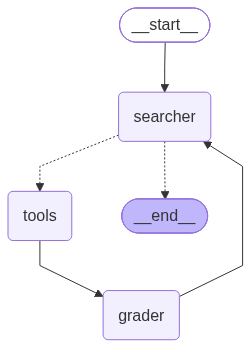

In [20]:
MAX_ROUNDS = 2   # max searches per researcher
def researcher_route(state: ResearcherState):
    if state.rounds >= MAX_ROUNDS:   
        return END
    return tools_condition(state)  

graph = StateGraph(ResearcherState , output_schema= ResearcherOutput)


graph.add_node("searcher",researcher_agent_node)
graph.add_node("grader",research_grader_node)
graph.add_node("tools", ToolNode(tools))

graph.add_edge(START,"searcher")
graph.add_conditional_edges("searcher",researcher_route,{"tools":"tools", END:END })
graph.add_edge("tools","grader")
graph.add_edge("grader", "searcher")

graph_researcher= graph.compile()
graph_researcher

## Main graph: fan-out, synthesizer, reflector

In [21]:
def send_researchers(state: MainState):
    return [Send("graph_researcher", {"question": state.question, "tool_name": tool.name})
            for tool in tools]


In [22]:
def strip_number(text: str) -> str:
    """'[2] Surah Al-Baqara (البقرة), 2:65-69\n...' -> 'Surah Al-Baqara (البقرة), 2:65-69\n...'
    (hadith results start with 'Hadith #...' and are returned unchanged)"""
    return re.sub(r"^\[\d+\]\s*", "", text)


def unique_sources(evidence: list[dict]) -> list[dict]:
    """Drop duplicate results: the same ayah passage, hadith or web page can be found
    by more than one search, each time with a different [n] number in front."""
    seen, sources = set(), []
    for e in evidence:
        key = strip_number(e["text"])
        if key not in seen:
            seen.add(key)
            sources.append(e)
    return sources


SOURCE_LABELS = {
    "quran_search_tool": "Quran",
    "hadith_search": "Hadith",
    "duck_duck_search": "Web",
}

MAX_SOURCES = 9      # sources given to the synthesizer / reflector (round-robin: 3 per tool)
SOURCE_CHARS = 600   # characters per source

def select_sources(evidence: list[dict]) -> list[dict]:
    """Unique sources, picked round-robin from each (question, tool) group so every
    researcher (and every follow-up question) is represented, capped at MAX_SOURCES.
    Deterministic: the synthesizer and reflector get the same list -> the same [n] numbers."""
    groups = {}
    for e in unique_sources(evidence):
        groups.setdefault((e["question"], e["tool"]), []).append(e)
    picked = []
    for i in range(max((len(g) for g in groups.values()), default=0)):
        for g in groups.values():
            if i < len(g) and len(picked) < MAX_SOURCES:
                picked.append(g[i])
    return picked


def format_sources(sources: list[dict]) -> str:
    """One global numbering [1] ... [n] across all researchers, tagged with the source type.
    Hadiths are shown as header + English text (short_view) to save tokens."""
    return "\n\n".join(
        f"[{n}] ({SOURCE_LABELS.get(s['tool'], s['tool'])})\n"
        f"{short_view(strip_number(s['text']), SOURCE_CHARS).replace('text_ar: ', '')}"
        for n, s in enumerate(sources, start=1)
    )


def reference_label(source: dict) -> str:
    """Short reference line for one source."""
    first_line = strip_number(source["text"]).splitlines()[0]
    if source["tool"] == "hadith_search":
        m = re.match(r"Hadith #(\d+)", first_line)
        return f"Sahih al-Bukhari, Hadith #{m.group(1)}" if m else first_line
    if source["tool"] == "quran_search_tool":
        return f"Quran: {first_line}"               
    return f"Web: {first_line}"                   


def build_references(answer: str, sources: list[dict]) -> str:
    """References list for the [n] numbers the answer actually cites."""
    cited = sorted({int(n) for n in re.findall(r"\[(\d+)\]", answer) if 1 <= int(n) <= len(sources)})
    if not cited:
        return ""
    lines = [f"[{n}] {reference_label(sources[n - 1])}" for n in cited]
    return "\n\n## References\n" + "\n".join(lines)

In [23]:
### Synthesizer
SYNTHESIZER_PROMPT = SystemMessage(content="""You are the Synthesizer for a Quran and Hadith research assistant.
Researchers have gathered numbered sources: Quran passages (Arabic), Sahih al-Bukhari hadiths, and web pages (tafsir, context).
Write the final answer to the user's question using ONLY these sources.

Rules:
- Base every statement on the sources. Do not use outside knowledge, and never quote a verse or hadith that is not in the sources.
- Cite every fact inline with its source number, like [1] or [2][5]. Only use numbers from the list.
- When you refer to a Quran passage, name the surah and ayah range exactly as the source gives it (e.g. Al-Baqara 2:65-69).
- Use Quran and hadith sources for the religious content, and web sources for explanation (tafsir) and context.
- Cover every part of the question. If the sources don't answer a part, say so honestly.
- If sources disagree, say so and explain the difference.
- Answer in the same language as the question. Answer directly first, then add supporting details. Be concise and respectful.
- Do NOT write a references list or a disclaimer; they are added automatically.""")

DISCLAIMER = ("\n\n---\nThis is an AI-assisted retrieval tool, not a scholarly ruling. "
              "For religious guidance, please consult a qualified scholar.")


def synthesizer_node(state: MainState) -> dict:
    sources = select_sources(state.evidence)
    request = f"Question: {state.question}\n\nSources:\n{format_sources(sources)}"

    if state.feedback:   # revise loop: show the previous draft and what to fix
        request += (f"\n\nYour previous draft:\n{state.answer}"
                    f"\n\nThe Reflector asked for these fixes:\n{state.feedback}"
                    "\n\nWrite the corrected answer.")

    answer = llm2.with_retry(**RETRY).invoke([SYNTHESIZER_PROMPT, HumanMessage(content=request)]).content
    return {"answer": answer + build_references(answer, sources) + DISCLAIMER}


### Reflector
class Reflection(BaseModel):
    decision: Literal["accept", "revise", "research_more"] = Field(
        description="accept = supported and complete; revise = fix the writing; research_more = information is missing")
    feedback: str = Field(
        description="For 'revise': which claims are unsupported or wrongly cited, and how to fix them. Empty otherwise.")
    follow_up_questions: list[str] = Field(
        description="For 'research_more': 1-2 self-contained questions covering only what is missing. Empty otherwise.")


REFLECTOR_PROMPT = SystemMessage(content="""You are the Reflector for a Quran and Hadith research assistant.
You review a draft answer against the numbered sources it was written from.

Check, in this order:
1. Support: every fact must have a citation [n], and source n must actually say it. Be strictest about religious content:
   a quoted or paraphrased verse/hadith that is not in its cited source, or a wrong surah:ayah or hadith number, is unsupported.
2. Coverage: the answer must cover every part of the user's question.
Ignore the "References" list and the disclaimer at the end; they are added automatically.

Then decide:
- accept: every fact is supported and every part of the question is covered. Minor style issues are fine.
- revise: the sources contain what is needed, but the answer has unsupported claims, wrong citations,
  or leaves out something the sources do say. Give specific feedback.
- research_more: the sources do NOT contain information needed for part of the question. Write 1-2 self-contained
  follow-up questions for only the missing parts, in the same language as the user's question
  (name the prophet, surah or concept instead of "he", "it" or "this"). Each one is sent to the Quran, hadith
  and web researchers.

Be strict about made-up facts and lenient about style.""")

reflector_llm = llm2.with_structured_output(Reflection).with_retry(**RETRY)


def reflector_node(state: MainState) -> dict:
    sources = select_sources(state.evidence)
    review = reflector_llm.invoke([REFLECTOR_PROMPT, HumanMessage(content=
        f"Question: {state.question}\n\n"
        f"Sources:\n{format_sources(sources)}\n\n"
        f"Draft answer:\n{state.answer}"
    )])

    return {
        "decision": review.decision,
        "feedback": review.feedback if review.decision == "revise" else "",
        "follow_ups": review.follow_up_questions[:2] if review.decision == "research_more" else [],
        "reflections": state.reflections + 1,
    }

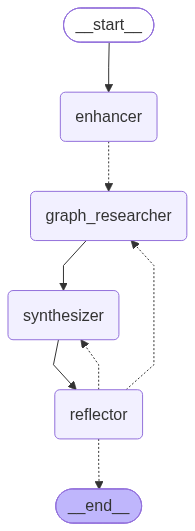

In [24]:
### Router after the reflector
LOOP_MAX = 3   # max reflector reviews before returning the latest draft

def router_after_reflection(state: MainState):
    if state.decision == "accept" or state.reflections >= LOOP_MAX:
        return END
    if state.decision == "revise":
        return "synthesizer"
    if state.follow_ups:
        # every follow-up question goes to all 3 researchers (one per tool), in parallel
        return [Send("graph_researcher", {"question": q, "tool_name": tool.name})
                for q in state.follow_ups for tool in tools]
    return END


### Full graph
full_graph = StateGraph(MainState)
full_graph.add_node("enhancer", enhancer_node)
full_graph.add_node("graph_researcher", graph_researcher)
full_graph.add_node("synthesizer", synthesizer_node)
full_graph.add_node("reflector", reflector_node)

full_graph.add_edge(START, "enhancer")
full_graph.add_conditional_edges("enhancer", send_researchers, ["graph_researcher"])
full_graph.add_edge("graph_researcher", "synthesizer")   # waits for all researchers
full_graph.add_edge("synthesizer", "reflector")
full_graph.add_conditional_edges("reflector", router_after_reflection, ["synthesizer", "graph_researcher", END])

grapher = full_graph.compile()
display(Image(grapher.get_graph().draw_mermaid_png()))

## Test

In [25]:
from collections import Counter

question = "ماذا يقول القرآن والسنة عن بر الوالدين؟"
result = grapher.invoke({"question": question})

print("User question:    ", question)
print("Enhanced question:", result["question"])
print("Evidence per tool:", dict(Counter(e["tool"] for e in result["evidence"])))
print("Follow-up questions:", result["follow_ups"] or "none")
print(f"Reviews: {result['reflections']}  |  last decision: {result['decision']}\n")
print(result["answer"])

User question:     ماذا يقول القرآن والسنة عن بر الوالدين؟
Enhanced question: ماذا يقول القرآن والسنة عن بر الوالدين؟
Evidence per tool: {'hadith_search': 2, 'duck_duck_search': 4, 'quran_search_tool': 1}
Follow-up questions: none
Reviews: 3  |  last decision: revise

القرآن والسنة يأمران ببرِّ الوالدين ويحذّران من عقوقهما، فالعقوق يُصنَّف من الكبائر وربما يُقارن بالشرك بالله [5][3].

**ما يورد القرآن**  
في سورة الإسراء (17:21‑25) يُؤمر المسلم أن يُحسِن إلى أمه وأبيه، لا يقال لهما «أف» ولا يُنهرهما، بل يُنادى عليهما بقولٍ كريم، ويُخفض لهما جناح الذل، ويُدعا لهما بالرحمة: «قُلْ رَبِّ ارْحَمْهُمَا كَمَا رَبَّيَانِي صَغِيرًا» [3].

**ما يورد السنة**  
- عن عبد الله بن عمرو أن رسول الله ﷺ قال: «إنّ من أعظم الكبائر أن يلعن الرجل والديه» [1]. فشرح الناس أن اللعن يكون بسبّ والد أحدهما لوالد الآخر والعكس.  
- في حديث آخر سأل رجل النبي ﷺ إذا كان والديه على قيد الحياة قبل أن يُكلف بالجهاد، فأجابه النبي ﷺ: «فاجْهَدْ في خدمتهما» [4]، أي أن خدمة الوالدين أولوية على غيرها من الأعمال.

**مكانة العقو